In [1]:
import pandas as pd

In [14]:
abt = pd.read_csv('./libras_abt.csv')
abt.info()
abt.head(3)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50186 entries, 0 to 50185
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   v0001   50186 non-null  int64  
 1   c006    50186 non-null  int64  
 2   c008    50186 non-null  int64  
 3   c009    50186 non-null  int64  
 4   d001    50186 non-null  int64  
 5   c011    50186 non-null  int64  
 6   d00901  50186 non-null  int64  
 7   g058    50186 non-null  int64  
 8   g05801  50186 non-null  int64  
 9   n       50186 non-null  float64
dtypes: float64(1), int64(9)
memory usage: 3.8 MB


,v0001,c006,c008,c009,d001,c011,d00901,g058,g05801,n
0,35,2,19,1,1,4,10,1,2,146977.555374
1,35,1,22,4,1,4,10,1,2,136834.935906
2,35,1,30,1,1,1,10,1,2,123619.327241


In [11]:
# https://stackoverflow.com/a/20250996
abt["g05801"].replace({1: "Yes", 2: "No"}, inplace=True)
abt.head(3)

,v0001,c006,c008,c009,d001,c011,d00901,g058,g05801,n
0,35,2,19,1,1,4,10,1,No,146977.555374
1,35,1,22,4,1,4,10,1,No,136834.935906
2,35,1,30,1,1,1,10,1,No,123619.327241


In [7]:
from pycaret.classification import *

In [12]:
s = setup(abt, target = 'g05801', session_id = 123)

,Description,Value
0,Session id,123
1,Target,g05801
2,Target type,Binary
3,Target mapping,"No: 0, Yes: 1"
4,Original data shape,"(50186, 10)"
5,Transformed data shape,"(50186, 10)"
6,Transformed train set shape,"(35130, 10)"
7,Transformed test set shape,"(15056, 10)"
8,Numeric features,9
9,Preprocess,True


In [20]:
# https://github.com/pycaret/pycaret/issues/1350#issuecomment-1261343673
#best = compare_models(fit_kwargs={'class_weights': abt['n']})
best = compare_models()

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
lr,Logistic Regression,0.9684,0.7890,0.9684,0.9377,0.9528,0.0000,0.0000,0.7390
ridge,Ridge Classifier,0.9684,0.7904,0.9684,0.9377,0.9528,0.0000,0.0000,0.0430
ada,Ada Boost Classifier,0.9684,0.7953,0.9684,0.9490,0.9531,0.0084,0.0375,0.2560
lda,Linear Discriminant Analysis,0.9684,0.7904,0.9684,0.9377,0.9528,0.0000,0.0000,0.0490
dummy,Dummy Classifier,0.9684,0.5000,0.9684,0.9377,0.9528,0.0000,0.0000,0.0460
lightgbm,Light Gradient Boosting Machine,0.9681,0.7957,0.9681,0.9471,0.9530,0.0109,0.0374,132.4070
gbc,Gradient Boosting Classifier,0.9680,0.8004,0.9680,0.9481,0.9529,0.0076,0.0335,0.9220
rf,Random Forest Classifier,0.9678,0.7398,0.9678,0.9447,0.9528,0.0086,0.0272,0.7200
knn,K Neighbors Classifier,0.9676,0.5467,0.9676,0.9428,0.9528,0.0098,0.0254,0.1070
nb,Naive Bayes,0.9650,0.7811,0.9650,0.9416,0.9520,0.0193,0.0297,0.0420


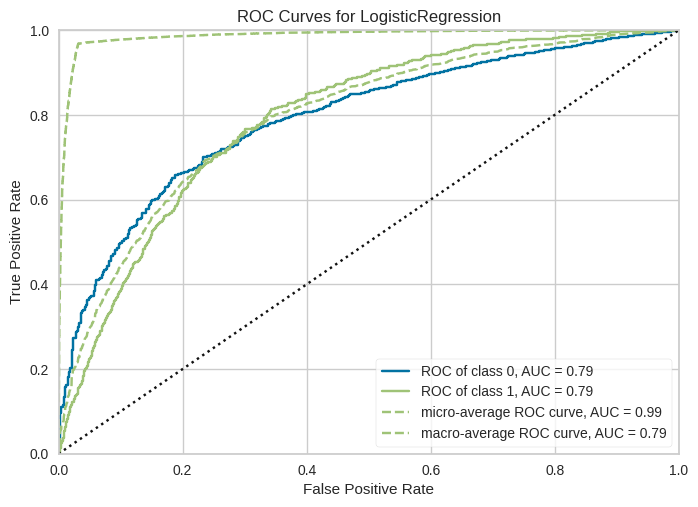

In [22]:
plot_model(best)